# CP5403 | Classification Fine-tuning GPT-2 on Vehicle Safety Complaints

**Objective:** Predict one of five reported NHTSA vehicle-system complaint categories from free-text `summary` descriptions.

**Project Dataset:** [vic35get/nhtsa_complaints_dataset](https://huggingface.co/datasets/vic35get/nhtsa_complaints_dataset) (Apache-2.0 as stated on its dataset card). The publisher describes five labels: `AIR BAGS`, `ELECTRICAL SYSTEM`, `OTHER`, `SERVICE BRAKES`, `STRUCTURE`. Publisher reports 12,534 total rows.

**Method:** Dataset audit → training split (before quality filtering) → TF-IDF baseline → pretrained `gpt2` + sequence-classification head → train selected parameters → validation → evaluation on held-out test → artifacts.


## 1 - Installing Dependencies and Capturing Environment
Package versions are pinned for reproducibility.

In [1]:
%pip -q install "transformers==4.57.3" "datasets==4.4.1" "accelerate>=1.3,<2" "scikit-learn>=1.4,<2" "pandas>=2,<3" "matplotlib>=3.7,<4"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.10.0 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


**Testing Installation**

In [2]:
import torch
import transformers
import datasets
import accelerate
import huggingface_hub

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments
)
from datasets import load_dataset

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("Accelerate:", accelerate.__version__)
print("Hugging Face Hub:", huggingface_hub.__version__)

print("SUCCESS: Essential libraries imported!")

PyTorch: 2.14.1+cu130
Transformers: 4.57.3
Datasets: 4.4.1
Accelerate: 1.15.0
Hugging Face Hub: 0.36.2
SUCCESS: Essential libraries imported!


In [3]:
import os, re, json, random, hashlib, shutil, sys, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset, Dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    DataCollatorWithPadding, Trainer, TrainingArguments, set_seed
)
import transformers, datasets, sklearn

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
DATASET_ID = "vic35get/nhtsa_complaints_dataset"
# Dataset commit reported in the public HF history; a fixed revision helps reproducibility.
DATASET_REVISION = "943738a6baf3e04027da6c199605782342f819b3"
BASE_MODEL = "gpt2"
USE_ALL_AVAILABLE_TRAINING = True  # all original train records after quality/leakage checks
MAX_LENGTH = 128
OUTPUT = Path("/content/automotive_cp5403_outputs") if Path("/content").exists() else Path("automotive_cp5403_outputs")
(OUTPUT / "data").mkdir(parents=True, exist_ok=True)
(OUTPUT / "figures").mkdir(parents=True, exist_ok=True)
(OUTPUT / "results").mkdir(parents=True, exist_ok=True)
(OUTPUT / "model").mkdir(parents=True, exist_ok=True)

versions = {
    "python": sys.version.split()[0], "torch": torch.__version__,
    "transformers": transformers.__version__, "datasets": datasets.__version__,
    "sklearn": sklearn.__version__, "pandas": pd.__version__,
    "dataset_id": DATASET_ID, "dataset_revision": DATASET_REVISION,
    "base_model": BASE_MODEL, "seed": SEED
}
(OUTPUT / "results" / "environment.json").write_text(json.dumps(versions, indent=2))
print(json.dumps(versions, indent=2))
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "transformers": "4.57.3",
  "datasets": "4.4.1",
  "sklearn": "1.6.1",
  "pandas": "2.2.3",
  "dataset_id": "vic35get/nhtsa_complaints_dataset",
  "dataset_revision": "943738a6baf3e04027da6c199605782342f819b3",
  "base_model": "gpt2",
  "seed": 42
}
GPU available: True
GPU: Tesla T4


## 2 - Downloading and Verifying the Public Source
**No access request or API key is required** for this public dataset.


In [4]:
raw = load_dataset(DATASET_ID, revision=DATASET_REVISION)
print(raw)
print("Splits available:", list(raw.keys()))
VAL_NAME = next((s for s in ["validation", "eval", "valid", "dev"] if s in raw), None)
if VAL_NAME is None or "train" not in raw or "test" not in raw:
    raise ValueError(f"Expected train, eval/validation and test. Found: {list(raw.keys())}")

frames = {"train": raw["train"].to_pandas(),
          "validation": raw[VAL_NAME].to_pandas(),
          "test": raw["test"].to_pandas()}
required = {"odiNumber", "summary", "label"}
for split, frame in frames.items():
    missing = required - set(frame.columns)
    if missing: raise ValueError(f"{split} is missing columns: {missing}")
    print(f"\n{split.upper()}: {len(frame):,} rows")
    print("Columns:", list(frame.columns))
    print(frame["label"].astype(str).value_counts(dropna=False).to_string())

ALL_LABELS = sorted(set().union(*(set(x["label"].dropna().astype(str)) for x in frames.values())))
assert len(ALL_LABELS) == 5, f"Expected five classes, found {ALL_LABELS}"
print("\nSource categories:", ALL_LABELS)
print("One example with metadata (text shortened):")
example = frames["train"].iloc[0]
print({"odiNumber": example["odiNumber"], "label": example["label"],
       "summary_excerpt": str(example["summary"])[:180]})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/2.29M [00:00<?, ?B/s]

data/eval-00000-of-00001.parquet:   0%|          | 0.00/572k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/456k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/8356 [00:00<?, ? examples/s]

Generating eval split:   0%|          | 0/2089 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2089 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['odiNumber', 'dateComplaintFiled', 'components', 'summary', 'label'],
        num_rows: 8356
    })
    eval: Dataset({
        features: ['odiNumber', 'dateComplaintFiled', 'components', 'summary', 'label'],
        num_rows: 2089
    })
    test: Dataset({
        features: ['odiNumber', 'dateComplaintFiled', 'components', 'summary', 'label'],
        num_rows: 2089
    })
})
Splits available: ['train', 'eval', 'test']

TRAIN: 8,356 rows
Columns: ['odiNumber', 'dateComplaintFiled', 'components', 'summary', 'label']
label
ELECTRICAL SYSTEM    1672
AIR BAGS             1671
OTHER                1671
STRUCTURE            1671
SERVICE BRAKES       1671

VALIDATION: 2,089 rows
Columns: ['odiNumber', 'dateComplaintFiled', 'components', 'summary', 'label']
label
OTHER                418
AIR BAGS             418
STRUCTURE            418
SERVICE BRAKES       418
ELECTRICAL SYSTEM    417

TEST: 2,089 rows
Columns: ['odiNumber', 'dateComplai

## 3 - Preparing the Data
**Only `summary` is a model input.** `components` is excluded because it reflects the target annotation and would create label leakage. `odiNumber` is used only for deduplication.

**Note:** The source is weakly labelled by component category. Holdout priority is **test → validation → train** for duplicated IDs and exactly normalised descriptions. It reduces direct leakage but does not eliminate paraphrase/near-duplicate leakage; this remains a limitation in the project.

In [5]:
def text_key(value):
    normalized = " ".join(str(value).casefold().split())
    return hashlib.sha256(normalized.encode("utf-8")).hexdigest()

def clean_split(df):
    original = len(df)
    x = df[["odiNumber", "summary", "label"]].copy()
    x = x.dropna(subset=["odiNumber", "summary", "label"])
    x["text"] = x["summary"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    x["label"] = x["label"].astype(str).str.strip()
    x = x[x["text"].str.len() >= 20].copy()
    x["text_key"] = x["text"].map(text_key)
    x["complaint_id"] = x["odiNumber"].astype(str)
    x = x.drop_duplicates(subset="complaint_id", keep="first")
    x = x.drop_duplicates(subset="text_key", keep="first")
    return x[["complaint_id", "text", "text_key", "label"]].reset_index(drop=True), original

cleaned = {}
quality_rows = []
for name in ("test", "validation", "train"):
    df, before = clean_split(frames[name])
    # Avoid any overlap with higher-priority holdout splits.
    for higher in ("test", "validation"):
        if higher in cleaned and higher != name:
            df = df[~df["complaint_id"].isin(set(cleaned[higher]["complaint_id"]))]
            df = df[~df["text_key"].isin(set(cleaned[higher]["text_key"]))]
    cleaned[name] = df.reset_index(drop=True)
    quality_rows.append({"split": name, "source_rows": before, "after_cleaning": len(df),
                         "removed": before - len(df)})

# Check mutually exclusive splits by complaint ID and normalised text.
for a,b in (("train","validation"),("train","test"),("validation","test")):
    assert set(cleaned[a].complaint_id).isdisjoint(cleaned[b].complaint_id)
    assert set(cleaned[a].text_key).isdisjoint(cleaned[b].text_key)

counts = cleaned["train"]["label"].value_counts()
print("Available unique training records per category (AFTER quality checks):")
print(counts.reindex(ALL_LABELS, fill_value=0).to_string())
if any(counts.get(label, 0) == 0 for label in ALL_LABELS):
    raise ValueError("At least one category has no clean training rows. Review data before training.")

# Source training split.
train_df = cleaned["train"].sample(frac=1, random_state=SEED).reset_index(drop=True)
print(f"Training rows retained: {len(train_df):,} / {len(frames['train']):,} source rows")
val_df = cleaned["validation"].copy()
test_df = cleaned["test"].copy()
assert 0 < len(train_df) <= len(frames["train"])
assert set(train_df["label"].unique()) == set(ALL_LABELS)
assert not train_df["complaint_id"].duplicated().any()
assert not train_df["text_key"].duplicated().any()

label2id = {name:i for i,name in enumerate(ALL_LABELS)}
id2label = {i:name for name,i in label2id.items()}
for df in (train_df, val_df, test_df):
    df["label_id"] = df["label"].map(label2id).astype(int)

# Copies of the Dataset remain in the Colab workspace.
for name, df in (("train_full",train_df), ("validation",val_df), ("test",test_df)):
    df[["complaint_id", "text", "label", "label_id"]].to_csv(OUTPUT / "data" / (name+".csv"), index=False)

quality = {"dataset": DATASET_ID, "revision": DATASET_REVISION,
           "training_selection": "All valid unique examples from original train split (no fixed sample cap)",
           "source_split_counts": {k: len(v) for k, v in frames.items()},
           "final_split_counts": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
           "quality_rows": quality_rows,
           "train_label_counts": train_df.label.value_counts().to_dict(),
           "validation_label_counts": val_df.label.value_counts().to_dict(),
           "test_label_counts": test_df.label.value_counts().to_dict(),
           "exclusions": "No components/ODI ID as model features; unique IDs and normalised text across splits"}
(OUTPUT / "results" / "data_quality.json").write_text(json.dumps(quality, indent=2))
print("\nData cleaning report:")
print(pd.DataFrame(quality_rows).to_string(index=False))
print("\nFinal split sizes:", {"train":len(train_df), "validation":len(val_df), "test":len(test_df)})
print("\nLabels:", label2id)


Available unique training records per category (AFTER quality checks):
label
AIR BAGS             1664
ELECTRICAL SYSTEM    1671
OTHER                1662
SERVICE BRAKES       1663
STRUCTURE            1660
Training rows retained: 8,320 / 8,356 source rows

Data cleaning report:
     split  source_rows  after_cleaning  removed
      test         2089            2074       15
validation         2089            2084        5
     train         8356            8320       36

Final split sizes: {'train': 8320, 'validation': 2084, 'test': 2074}

Labels: {'AIR BAGS': 0, 'ELECTRICAL SYSTEM': 1, 'OTHER': 2, 'SERVICE BRAKES': 3, 'STRUCTURE': 4}


## 4 - Visualising Class Imbalance
The source training split was balanced by its curator; after deduplication class counts may differ slightly. The test set which were held-out deliberately retains the source's natural class skew, apart from leakage/duplicate removals.

,train_full,validation,test
label,,,
AIR BAGS,1664,416,99
ELECTRICAL SYSTEM,1671,417,156
OTHER,1662,417,1689
SERVICE BRAKES,1663,418,17
STRUCTURE,1660,416,113


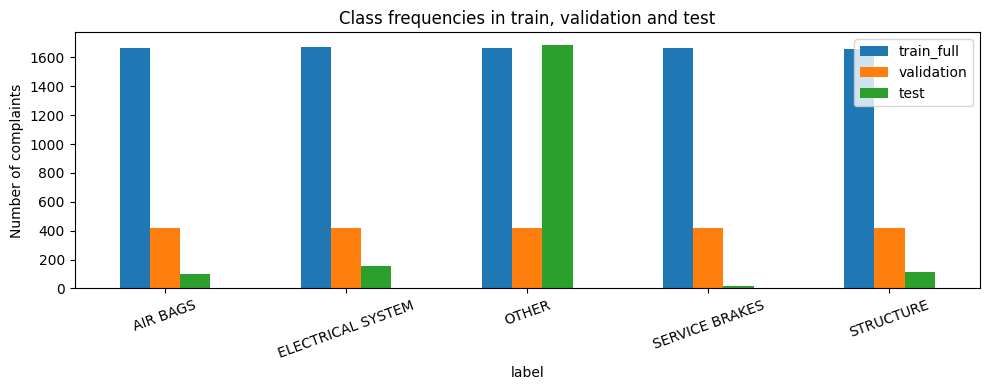

In [6]:
count_table = pd.DataFrame({
    "train_full": train_df.label.value_counts(),
    "validation": val_df.label.value_counts(),
    "test": test_df.label.value_counts()
}).reindex(ALL_LABELS).fillna(0).astype(int)
display(count_table)
axes = count_table.plot(kind="bar", figsize=(10,4), rot=20)
axes.set_title("Class frequencies in train, validation and test")
axes.set_ylabel("Number of complaints")
plt.tight_layout()
plt.savefig(OUTPUT/"figures"/"class_distribution.png", dpi=180)
plt.show()

## 5 - Establishing a Conventional Baseline *before* Transformer Fine-tuning
TF-IDF + logistic regression provides a baseline.

In [7]:
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=30000, sublinear_tf=True)),
    ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED))
])
baseline.fit(train_df["text"], train_df["label_id"])
base_val_pred = baseline.predict(val_df["text"])

def metric_dict(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(len(ALL_LABELS))),
        average="macro", zero_division=0)
    return {"accuracy":float(accuracy_score(y_true,y_pred)),
            "precision_macro":float(p), "recall_macro":float(r), "f1_macro":float(f)}

baseline_val_metrics = metric_dict(val_df["label_id"], base_val_pred)
print("Baseline VALIDATION metrics:", baseline_val_metrics)
print(classification_report(val_df["label_id"], base_val_pred,
      labels=list(range(len(ALL_LABELS))), target_names=ALL_LABELS, zero_division=0))

Baseline VALIDATION metrics: {'accuracy': 0.8426103646833013, 'precision_macro': 0.8412373181859131, 'recall_macro': 0.842643022129959, 'f1_macro': 0.841444086185752}
                   precision    recall  f1-score   support

         AIR BAGS       0.91      0.94      0.93       416
ELECTRICAL SYSTEM       0.85      0.82      0.83       417
            OTHER       0.67      0.64      0.65       417
   SERVICE BRAKES       0.95      0.93      0.94       418
        STRUCTURE       0.83      0.89      0.86       416

         accuracy                           0.84      2084
        macro avg       0.84      0.84      0.84      2084
     weighted avg       0.84      0.84      0.84      2084



## 6 - Building Pretrained GPT-2 Sequence Classifier
A pretrained GPT-2 is loaded and receives a newly initialised 5-logit classification layer. I **freeze the earlier blocks and fine-tune the final block, final normalisation and new classification head.** The output layer has five units (one per label)

In [8]:
if not torch.cuda.is_available():
    raise RuntimeError("No GPU found. In Colab choose Runtime > Change runtime type > T4 GPU, then rerun.")

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)
tokenizer.pad_token = tokenizer.eos_token
model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL, num_labels=len(ALL_LABELS), id2label=id2label,
    label2id=label2id
)
model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False

for param in model.parameters():
    param.requires_grad = False
for param in model.transformer.h[-1].parameters():
    param.requires_grad = True
for param in model.transformer.ln_f.parameters():
    param.requires_grad = True
for param in model.score.parameters():
    param.requires_grad = True

num_total = sum(p.numel() for p in model.parameters())
num_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {num_total:,}")
print(f"Fine-tuned parameters: {num_trainable:,} ({num_trainable/num_total:.1%})")
print("Classification labels:", model.config.id2label)
assert model.score.out_features == 5
assert num_trainable > 0 and num_trainable < num_total

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Total parameters: 124,443,648
Fine-tuned parameters: 7,093,248 (5.7%)
Classification labels: {0: 'AIR BAGS', 1: 'ELECTRICAL SYSTEM', 2: 'OTHER', 3: 'SERVICE BRAKES', 4: 'STRUCTURE'}


## 7 - Tokenising Inputs for Training, Validation and Test
I use the pretrained GPT-2 tokenizer, retain at most 128 tokens per complaint, and dynamically pad batches to avoid wasted GPU memory.

In [9]:
def make_hf(df):
    temp = df[["text", "label_id"]].rename(columns={"label_id":"labels"})
    return Dataset.from_pandas(temp, preserve_index=False)

def tokenize_batch(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

train_tokens = make_hf(train_df).map(tokenize_batch, batched=True, remove_columns=["text"])
val_tokens = make_hf(val_df).map(tokenize_batch, batched=True, remove_columns=["text"])
test_tokens = make_hf(test_df).map(tokenize_batch, batched=True, remove_columns=["text"])
collator = DataCollatorWithPadding(tokenizer=tokenizer, padding=True)

# Truncation audit: approximate percentage of original tokenised training texts above 128 tokens.
lengths = [len(tokenizer.encode(s, add_special_tokens=False)) for s in train_df["text"]]
truncated = sum(n>MAX_LENGTH for n in lengths)
print(f"Training descriptions longer than {MAX_LENGTH} tokens: {truncated}/{len(lengths)} ({truncated/len(lengths):.1%})")
print("Train token columns:", train_tokens.column_names)
print("Sample encoded length:", len(train_tokens[0]["input_ids"]))
quality["train_longer_than_max_tokens"] = truncated
quality["max_length"] = MAX_LENGTH
(OUTPUT / "results" / "data_quality.json").write_text(json.dumps(quality, indent=2))

Map:   0%|          | 0/8320 [00:00<?, ? examples/s]

Map:   0%|          | 0/2084 [00:00<?, ? examples/s]

Map:   0%|          | 0/2074 [00:00<?, ? examples/s]

Training descriptions longer than 128 tokens: 1955/8320 (23.5%)
Train token columns: ['labels', 'input_ids', 'attention_mask']
Sample encoded length: 37


1380

## 8 - Fine-tuning Selected Model Parameters


In [10]:
def compute_metrics(eval_pred):
    logits = eval_pred.predictions
    if isinstance(logits, tuple):
        logits = logits[0]
    predicted = np.argmax(logits, axis=-1)
    return metric_dict(eval_pred.label_ids, predicted)

bf16_ok = bool(getattr(torch.cuda, "is_bf16_supported", lambda:False)())
args = TrainingArguments(
    output_dir=str(OUTPUT/"checkpoints"),
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    gradient_accumulation_steps=2,
    learning_rate=5e-5,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=25,
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    fp16=not bf16_ok,
    bf16=bf16_ok,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
    remove_unused_columns=True
)
trainer = Trainer(
    model=model, args=args, train_dataset=train_tokens,
    eval_dataset=val_tokens,
    data_collator=collator, processing_class=tokenizer,
    compute_metrics=compute_metrics
)
import time
start_training = time.perf_counter()
training_output = trainer.train()
training_duration_seconds = time.perf_counter() - start_training
print(f"Fine-tuning duration (seconds): {training_duration_seconds:.1f}")
print("Training summary:", training_output.metrics)
print("Selected checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation macro-F1:", trainer.state.best_metric)
model.save_pretrained(OUTPUT/"model"/"gpt2_vehicle_complaints")
tokenizer.save_pretrained(OUTPUT/"model"/"gpt2_vehicle_complaints")

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.827900,0.788358,0.714491,0.695529,0.714537,0.695905
2,0.639000,0.677072,0.755758,0.747050,0.755787,0.748380


Fine-tuning duration (seconds): 334.1
Training summary: {'train_runtime': 333.6226, 'train_samples_per_second': 49.877, 'train_steps_per_second': 3.117, 'total_flos': 1072370497720320.0, 'train_loss': 1.4026978795345013, 'epoch': 2.0}
Selected checkpoint: /content/automotive_cp5403_outputs/checkpoints/checkpoint-1040
Best validation macro-F1: 0.7483804661123129


('/content/automotive_cp5403_outputs/model/gpt2_vehicle_complaints/tokenizer_config.json',
 '/content/automotive_cp5403_outputs/model/gpt2_vehicle_complaints/special_tokens_map.json',
 '/content/automotive_cp5403_outputs/model/gpt2_vehicle_complaints/vocab.json',
 '/content/automotive_cp5403_outputs/model/gpt2_vehicle_complaints/merges.txt',
 '/content/automotive_cp5403_outputs/model/gpt2_vehicle_complaints/added_tokens.json',
 '/content/automotive_cp5403_outputs/model/gpt2_vehicle_complaints/tokenizer.json')

**Preserving Experiment 1**

In [11]:

# Preserve the 128-token experiment (Experiment 1).

import gc
import json
from pathlib import Path

RUN1_MODEL_DIR = OUTPUT / "model" / "gpt2_vehicle_complaints"
RUN1_RESULTS_DIR = OUTPUT / "experiments" / "gpt2_128tokens_2epochs"
RUN1_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Confirm original trained model is safely stored.
assert (RUN1_MODEL_DIR / "config.json").exists(), \
    "Original model configuration was not found."

assert any(RUN1_MODEL_DIR.glob("*.safetensors")), \
    "Original trained model weights were not found."

# Validate Experiment 1 again (NOT the test dataset).
run1_eval = trainer.evaluate(eval_dataset=val_tokens)

run1_metrics = {
    "experiment": "GPT-2 / 128 tokens / 2 epochs",
    "max_length": 128,
    "epochs": 2,
    "training_samples": len(train_df),
    "validation_samples": len(val_df),
    "accuracy": float(run1_eval["eval_accuracy"]),
    "f1_macro": float(run1_eval["eval_f1_macro"]),
    "validation_loss": float(run1_eval["eval_loss"]),
    "training_seconds": float(training_duration_seconds),
    "saved_model_path": str(RUN1_MODEL_DIR)
}

# Save original results and training history.
(RUN1_RESULTS_DIR / "validation_metrics.json").write_text(
    json.dumps(run1_metrics, indent=2)
)

pd.DataFrame(trainer.state.log_history).to_csv(
    RUN1_RESULTS_DIR / "training_history.csv",
    index=False
)

print("EXPERIMENT 1 PRESERVED")
print(json.dumps(run1_metrics, indent=2))

# Release GPU memory. The original model remains on disk.
del trainer
del model

gc.collect()
torch.cuda.empty_cache()

print("GPU memory cleared for Experiment 2.")
print("Original model remains saved at:", RUN1_MODEL_DIR)


EXPERIMENT 1 PRESERVED
{
  "experiment": "GPT-2 / 128 tokens / 2 epochs",
  "max_length": 128,
  "epochs": 2,
  "training_samples": 8320,
  "validation_samples": 2084,
  "accuracy": 0.7557581573896354,
  "f1_macro": 0.7483804661123129,
  "validation_loss": 0.6770718097686768,
  "training_seconds": 334.10247978600023,
  "saved_model_path": "/content/automotive_cp5403_outputs/model/gpt2_vehicle_complaints"
}
GPU memory cleared for Experiment 2.
Original model remains saved at: /content/automotive_cp5403_outputs/model/gpt2_vehicle_complaints


**Tokenising the same data using 256 tokens**

In [14]:

# Retokenise the original training and validation data.
# The test set remains unused for model selection.

MAX_LENGTH_V2 = 256

def tokenize_v2(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH_V2
    )

train_tokens_v2 = make_hf(train_df).map(
    tokenize_v2,
    batched=True,
    remove_columns=["text"]
)

val_tokens_v2 = make_hf(val_df).map(
    tokenize_v2,
    batched=True,
    remove_columns=["text"]
)

# Compare truncation at 128 versus 256 tokens.
long_128 = sum(n > 128 for n in lengths)
long_256 = sum(n > 256 for n in lengths)

print("Training samples:", len(train_tokens_v2))
print("Validation samples:", len(val_tokens_v2))

print(
    "Descriptions longer than 128 tokens:",
    long_128,
    f"({long_128 / len(lengths):.1%})"
)

print(
    "Descriptions longer than 256 tokens:",
    long_256,
    f"({long_256 / len(lengths):.1%})"
)

print("Experiment 2 tokenisation completed.")


Map:   0%|          | 0/8320 [00:00<?, ? examples/s]

Map:   0%|          | 0/2084 [00:00<?, ? examples/s]

Training samples: 8320
Validation samples: 2084
Descriptions longer than 128 tokens: 1955 (23.5%)
Descriptions longer than 256 tokens: 439 (5.3%)
Experiment 2 tokenisation completed.


**Checking how many complaints exceed 256 tokens**

In [13]:

# Check the effect of different maximum token lengths

import pandas as pd

token_limits = [128, 192, 256, 320, 384, 512]

results = []

for limit in token_limits:
    count = sum(length > limit for length in lengths)
    percentage = (count / len(lengths)) * 100

    results.append({
        "Maximum tokens": limit,
        "Descriptions truncated": count,
        "Truncated (%)": round(percentage, 2),
        "Descriptions fully retained (%)": round(
            100 - percentage, 2
        )
    })

token_comparison = pd.DataFrame(results)

display(token_comparison)


,Maximum tokens,Descriptions truncated,Truncated (%),Descriptions fully retained (%)
0,128,1955,23.50,76.50
1,192,826,9.93,90.07
2,256,439,5.28,94.72
3,320,250,3.00,97.00
4,384,115,1.38,98.62
5,512,1,0.01,99.99


**Experiment 2 - Fine-tuning GPT-2 again**

In [15]:

# EXPERIMENT 2
# GPT-2 classification fine-tuning.
# Fresh pretrained weights, 256 tokens, 3 epochs.

import time

set_seed(SEED)

RUN2_DIR = OUTPUT / "experiments" / "gpt2_256tokens_3epochs"
RUN2_DIR.mkdir(parents=True, exist_ok=True)

model2 = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL,
    num_labels=len(ALL_LABELS),
    id2label=id2label,
    label2id=label2id
)

model2.config.pad_token_id = tokenizer.pad_token_id
model2.config.use_cache = False

# Freeze all parameters initially.
for param in model2.parameters():
    param.requires_grad = False

# Fine-tune the final Transformer block.
for param in model2.transformer.h[-1].parameters():
    param.requires_grad = True

# Fine-tune final normalisation.
for param in model2.transformer.ln_f.parameters():
    param.requires_grad = True

# Fine-tune the classification head.
for param in model2.score.parameters():
    param.requires_grad = True

trainable_v2 = sum(
    p.numel() for p in model2.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_v2)

bf16_v2 = bool(
    getattr(torch.cuda, "is_bf16_supported", lambda: False)()
)

args_v2 = TrainingArguments(
    output_dir=str(RUN2_DIR / "checkpoints"),
    num_train_epochs=3,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=4,
    learning_rate=5e-5,
    weight_decay=0.01,
    warmup_ratio=0.1,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=25,
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1_macro",
    greater_is_better=True,
    save_total_limit=1,
    fp16=not bf16_v2,
    bf16=bf16_v2,
    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0,
    remove_unused_columns=True
)

trainer2 = Trainer(
    model=model2,
    args=args_v2,
    train_dataset=train_tokens_v2,
    eval_dataset=val_tokens_v2,
    data_collator=collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

# Run the second fine-tuning experiment.
start_v2 = time.perf_counter()

training_output_v2 = trainer2.train()

run2_duration_seconds = (
    time.perf_counter() - start_v2
)

# VALIDATION ONLY - no test evaluation.
run2_eval = trainer2.evaluate(
    eval_dataset=val_tokens_v2
)

# Record actual results.
run2_metrics = {
    "experiment": "GPT-2 / 256 tokens / 3 epochs",
    "max_length": 256,
    "epochs": 3,
    "training_samples": len(train_df),
    "validation_samples": len(val_df),
    "accuracy": float(run2_eval["eval_accuracy"]),
    "f1_macro": float(run2_eval["eval_f1_macro"]),
    "validation_loss": float(run2_eval["eval_loss"]),
    "training_seconds": float(run2_duration_seconds),
    "best_checkpoint": trainer2.state.best_model_checkpoint,
    "trainable_parameters": trainable_v2
}

# Save the new model separately.
RUN2_MODEL_DIR = RUN2_DIR / "model"

trainer2.model.save_pretrained(RUN2_MODEL_DIR)
tokenizer.save_pretrained(RUN2_MODEL_DIR)

# Save reproducibility evidence.
(RUN2_DIR / "validation_metrics.json").write_text(
    json.dumps(run2_metrics, indent=2)
)

pd.DataFrame(
    trainer2.state.log_history
).to_csv(
    RUN2_DIR / "training_history.csv",
    index=False
)

# Compare both fine-tuned models and the baseline.
comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": baseline_val_metrics["accuracy"],
        "Macro_F1": baseline_val_metrics["f1_macro"]
    },
    {
        "Model": "GPT-2 Experiment 1 (128 tokens)",
        "Accuracy": run1_metrics["accuracy"],
        "Macro_F1": run1_metrics["f1_macro"]
    },
    {
        "Model": "GPT-2 Experiment 2 (256 tokens)",
        "Accuracy": run2_metrics["accuracy"],
        "Macro_F1": run2_metrics["f1_macro"]
    }
])

comparison.to_csv(
    OUTPUT / "results" / "validation_experiment_comparison.csv",
    index=False
)

print("\nEXPERIMENT 2 COMPLETED")
print(json.dumps(run2_metrics, indent=2))

print("\nVALIDATION MODEL COMPARISON")
display(comparison)

print("\nBest checkpoint:", trainer2.state.best_model_checkpoint)
print("Experiment 2 saved at:", RUN2_MODEL_DIR)


Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Trainable parameters: 7093248


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.758100,0.694179,0.737044,0.723125,0.737096,0.718471
2,0.624300,0.575593,0.797505,0.792167,0.797542,0.792742


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.758100,0.694179,0.737044,0.723125,0.737096,0.718471
2,0.624300,0.575593,0.797505,0.792167,0.797542,0.792742
3,0.518800,0.556174,0.803263,0.796781,0.803303,0.797952



EXPERIMENT 2 COMPLETED
{
  "experiment": "GPT-2 / 256 tokens / 3 epochs",
  "max_length": 256,
  "epochs": 3,
  "training_samples": 8320,
  "validation_samples": 2084,
  "accuracy": 0.8032629558541267,
  "f1_macro": 0.7979516413890053,
  "validation_loss": 0.5561743974685669,
  "training_seconds": 752.0402344550002,
  "best_checkpoint": "/content/automotive_cp5403_outputs/experiments/gpt2_256tokens_3epochs/checkpoints/checkpoint-1560",
  "trainable_parameters": 7093248
}

VALIDATION MODEL COMPARISON


,Model,Accuracy,Macro_F1
0,TF-IDF + Logistic Regression,0.842610,0.841444
1,GPT-2 Experiment 1 (128 tokens),0.755758,0.748380
2,GPT-2 Experiment 2 (256 tokens),0.803263,0.797952



Best checkpoint: /content/automotive_cp5403_outputs/experiments/gpt2_256tokens_3epochs/checkpoints/checkpoint-1560
Experiment 2 saved at: /content/automotive_cp5403_outputs/experiments/gpt2_256tokens_3epochs/model


**Experiment 3 - Fine-tuning GPT-2 again**

In [16]:

# EXPERIMENT 3
# GPT-2 classification fine-tuning:
# 256 tokens, up to 5 epochs, last 3 Transformer blocks,
# separate learning rates and early stopping.

import gc
import json
import time
import torch
import pandas as pd

from transformers import (
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback,
    set_seed
)

# Confirm Experiment 2 is already saved.
assert (RUN2_MODEL_DIR / "config.json").exists()
assert any(RUN2_MODEL_DIR.glob("*.safetensors"))

# Keep all existing Experiment 2 results and checkpoints.
if "trainer2" in globals():
    del trainer2

if "model2" in globals():
    del model2

gc.collect()
torch.cuda.empty_cache()

set_seed(SEED)

# Separate experiment directory.
RUN3_DIR = OUTPUT / "experiments" / "gpt2_256tokens_5epochs_3blocks"
RUN3_DIR.mkdir(parents=True, exist_ok=True)

# Load fresh original pretrained GPT-2 weights.
model3 = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL,
    num_labels=len(ALL_LABELS),
    id2label=id2label,
    label2id=label2id
)

model3.config.pad_token_id = tokenizer.pad_token_id
model3.config.use_cache = False

# Freeze all parameters first.
for param in model3.parameters():
    param.requires_grad = False

# Unfreeze the final three Transformer blocks.
for block in model3.transformer.h[-3:]:
    for param in block.parameters():
        param.requires_grad = True

# Unfreeze final normalisation.
for param in model3.transformer.ln_f.parameters():
    param.requires_grad = True

# Unfreeze classification head.
for param in model3.score.parameters():
    param.requires_grad = True

# Count trainable parameters.
trainable3 = sum(
    p.numel() for p in model3.parameters()
    if p.requires_grad
)

print("Trainable parameters:", f"{trainable3:,}")

# Different learning rates for pretrained layers and new head.
backbone_params = [
    p for name, p in model3.named_parameters()
    if p.requires_grad and not name.startswith("score.")
]

head_params = [
    p for name, p in model3.named_parameters()
    if p.requires_grad and name.startswith("score.")
]

optimizer3 = torch.optim.AdamW(
    [
        {"params": backbone_params, "lr": 2e-5},
        {"params": head_params, "lr": 2e-4}
    ],
    weight_decay=0.01
)

bf16_v3 = bool(
    getattr(torch.cuda, "is_bf16_supported", lambda: False)()
)

args3 = TrainingArguments(
    output_dir=str(RUN3_DIR / "checkpoints"),
    num_train_epochs=5,

    per_device_train_batch_size=2,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=8,

    learning_rate=2e-5,
    warmup_ratio=0.1,
    weight_decay=0.01,
    max_grad_norm=1.0,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="eval_f1_macro",
    greater_is_better=True,

    save_total_limit=2,
    logging_steps=25,

    fp16=not bf16_v3,
    bf16=bf16_v3,

    report_to="none",
    seed=SEED,
    data_seed=SEED,
    dataloader_num_workers=0
)

trainer3 = Trainer(
    model=model3,
    args=args3,
    train_dataset=train_tokens_v2,
    eval_dataset=val_tokens_v2,
    data_collator=collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,

    optimizers=(optimizer3, None),

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2,
            early_stopping_threshold=0.001
        )
    ]
)

# Train using the validation set only for model selection.
start3 = time.perf_counter()

train_result3 = trainer3.train()

duration3 = time.perf_counter() - start3

# Evaluate the selected checkpoint on validation.
val_result3 = trainer3.evaluate(
    eval_dataset=val_tokens_v2
)

run3_metrics = {
    "experiment": "GPT-2 / 256 tokens / up to 5 epochs / 3 blocks",
    "max_length": 256,
    "max_epochs": 5,
    "trainable_parameters": trainable3,
    "training_samples": len(train_df),
    "validation_samples": len(val_df),
    "accuracy": float(val_result3["eval_accuracy"]),
    "f1_macro": float(val_result3["eval_f1_macro"]),
    "validation_loss": float(val_result3["eval_loss"]),
    "training_seconds": float(duration3),
    "best_checkpoint": trainer3.state.best_model_checkpoint
}

# Save the Experiment 3 model.
RUN3_MODEL_DIR = RUN3_DIR / "model"

trainer3.model.save_pretrained(RUN3_MODEL_DIR)
tokenizer.save_pretrained(RUN3_MODEL_DIR)

(RUN3_DIR / "validation_metrics.json").write_text(
    json.dumps(run3_metrics, indent=2)
)

pd.DataFrame(
    trainer3.state.log_history
).to_csv(
    RUN3_DIR / "training_history.csv",
    index=False
)

# Compare all models using the SAME validation set.
comparison3 = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        "Accuracy": baseline_val_metrics["accuracy"],
        "Macro_F1": baseline_val_metrics["f1_macro"]
    },
    {
        "Model": "GPT-2 Experiment 1",
        "Accuracy": run1_metrics["accuracy"],
        "Macro_F1": run1_metrics["f1_macro"]
    },
    {
        "Model": "GPT-2 Experiment 2",
        "Accuracy": run2_metrics["accuracy"],
        "Macro_F1": run2_metrics["f1_macro"]
    },
    {
        "Model": "GPT-2 Experiment 3",
        "Accuracy": run3_metrics["accuracy"],
        "Macro_F1": run3_metrics["f1_macro"]
    }
])

comparison3.to_csv(
    OUTPUT / "results" / "validation_comparison_3experiments.csv",
    index=False
)

print("\nEXPERIMENT 3 COMPLETED")
print(json.dumps(run3_metrics, indent=2))

print("\nVALIDATION COMPARISON")
display(comparison3)

print("\nBest checkpoint:",
      trainer3.state.best_model_checkpoint)


Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Trainable parameters: 21,268,992


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.545900,0.557568,0.802783,0.796866,0.802819,0.788870


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro
1,0.545900,0.557568,0.802783,0.796866,0.802819,0.788870
2,0.432600,0.440289,0.849808,0.844283,0.849847,0.842371
3,0.366500,0.430464,0.853167,0.847539,0.853198,0.845933
4,0.445400,0.420770,0.858925,0.853949,0.858957,0.853509
5,0.331000,0.416437,0.859405,0.854180,0.859433,0.854378



EXPERIMENT 3 COMPLETED
{
  "experiment": "GPT-2 / 256 tokens / up to 5 epochs / 3 blocks",
  "max_length": 256,
  "max_epochs": 5,
  "trainable_parameters": 21268992,
  "training_samples": 8320,
  "validation_samples": 2084,
  "accuracy": 0.8594049904030711,
  "f1_macro": 0.8543783343895661,
  "validation_loss": 0.4164372980594635,
  "training_seconds": 1386.6426438429999,
  "best_checkpoint": "/content/automotive_cp5403_outputs/experiments/gpt2_256tokens_5epochs_3blocks/checkpoints/checkpoint-2600"
}

VALIDATION COMPARISON


,Model,Accuracy,Macro_F1
0,TF-IDF + Logistic Regression,0.842610,0.841444
1,GPT-2 Experiment 1,0.755758,0.748380
2,GPT-2 Experiment 2,0.803263,0.797952
3,GPT-2 Experiment 3,0.859405,0.854378



Best checkpoint: /content/automotive_cp5403_outputs/experiments/gpt2_256tokens_5epochs_3blocks/checkpoints/checkpoint-2600


## 9 - Validating the Fine-tuned Model, then Evaluating on the Untouched Test Set
The trained Transformer and baseline are now compared on the original holdout test set. Because `OTHER` dominates the test set, report **macro-F1** and class recalls prominently.

In [17]:

# SECTION 9 — FINAL TEST EVALUATION
# Selected model: GPT-2 Experiment 3
# 256 tokens, 5 epochs, final 3 Transformer blocks

import json
import numpy as np
import pandas as pd

from sklearn.metrics import classification_report

# Verify the selected Experiment 3 model.
assert trainer3.state.best_model_checkpoint is not None
assert len(test_df) == 2074
assert MAX_LENGTH_V2 == 256

# Tokenise the untouched test dataset using 256 tokens.
test_tokens_v3 = make_hf(test_df).map(
    tokenize_v2,
    batched=True,
    remove_columns=["text"]
)

# Generate GPT-2 predictions.
gpt_test_output = trainer3.predict(test_tokens_v3)

gpt_logits = gpt_test_output.predictions

if isinstance(gpt_logits, tuple):
    gpt_logits = gpt_logits[0]

gpt_test_pred = np.argmax(gpt_logits, axis=-1)

# Generate baseline predictions on the same test records.
base_test_pred = baseline.predict(test_df["text"])

# Calculate identical metrics for both models.
gpt_test_metrics = metric_dict(
    test_df["label_id"],
    gpt_test_pred
)

baseline_test_metrics = metric_dict(
    test_df["label_id"],
    base_test_pred
)

# Compare results.
final_comparison = pd.DataFrame([
    {
        "Model": "TF-IDF + Logistic Regression",
        **baseline_test_metrics
    },
    {
        "Model": "Fine-tuned GPT-2 Experiment 3",
        **gpt_test_metrics
    }
])

# Save evaluation evidence.
results_dir = OUTPUT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

final_comparison.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

final_metrics = {
    "dataset": DATASET_ID,
    "dataset_revision": DATASET_REVISION,
    "training_samples": len(train_df),
    "validation_samples": len(val_df),
    "test_samples": len(test_df),
    "selected_model": "GPT-2 Experiment 3",
    "max_tokens": 256,
    "training_epochs": 5,
    "trainable_parameters": 21268992,
    "baseline_validation": baseline_val_metrics,
    "gpt2_validation": run3_metrics,
    "baseline_test": baseline_test_metrics,
    "gpt2_test": gpt_test_metrics
}

(results_dir / "metrics.json").write_text(
    json.dumps(final_metrics, indent=2)
)

# Save per-class results.
for name, predictions in [
    ("gpt2", gpt_test_pred),
    ("baseline", base_test_pred)
]:
    report = classification_report(
        test_df["label_id"],
        predictions,
        labels=list(range(len(ALL_LABELS))),
        target_names=ALL_LABELS,
        output_dict=True,
        zero_division=0
    )

    pd.DataFrame({
        key: value
        for key, value in report.items()
        if isinstance(value, dict)
    }).T.to_csv(
        results_dir / f"{name}_test_per_class_report.csv"
    )

# Save predictions without vehicle complaint text.
pd.DataFrame({
    "test_row_index": np.arange(len(test_df)),
    "true_label": test_df["label"].to_numpy(),
    "gpt2_prediction": [
        id2label[int(i)] for i in gpt_test_pred
    ],
    "baseline_prediction": [
        id2label[int(i)] for i in base_test_pred
    ]
}).to_csv(
    results_dir / "test_predictions_labels_only.csv",
    index=False
)

print("\nFINAL TEST MODEL COMPARISON")
display(final_comparison)

print("\nGPT-2 TEST CLASSIFICATION REPORT")
print(classification_report(
    test_df["label_id"],
    gpt_test_pred,
    labels=list(range(len(ALL_LABELS))),
    target_names=ALL_LABELS,
    zero_division=0
))

print("\nBASELINE TEST CLASSIFICATION REPORT")
print(classification_report(
    test_df["label_id"],
    base_test_pred,
    labels=list(range(len(ALL_LABELS))),
    target_names=ALL_LABELS,
    zero_division=0
))

print("\nFinal independent test evaluation completed.")


Map:   0%|          | 0/2074 [00:00<?, ? examples/s]

AttributeError: 'float' object has no attribute 'items'

**Fix Classification Report**

In [19]:
# SECTION 9 - FIX SAVING FOR CLASSIFICATION REPORT

import pandas as pd
import numpy as np
from sklearn.metrics import classification_report

# Check that test predictions already exist.
assert "gpt_test_pred" in globals()
assert "base_test_pred" in globals()

assert len(gpt_test_pred) == len(test_df)
assert len(base_test_pred) == len(test_df)

results_dir = OUTPUT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

# Save classification reports for both models.
for name, predictions in [
    ("gpt2", gpt_test_pred),
    ("baseline", base_test_pred)
]:
    report = classification_report(
        test_df["label_id"],
        predictions,
        labels=list(range(len(ALL_LABELS))),
        target_names=ALL_LABELS,
        output_dict=True,
        zero_division=0
    )

    # Keep only dictionary-valued results.
    report_df = pd.DataFrame({
        key: value
        for key, value in report.items()
        if isinstance(value, dict)
    }).T

    report_df.to_csv(
        results_dir / f"{name}_test_per_class_report.csv"
    )

# Save predictions without the original complaint text.
pd.DataFrame({
    "test_row_index": np.arange(len(test_df)),
    "true_label": test_df["label"].to_numpy(),
    "gpt2_prediction": [
        id2label[int(i)] for i in gpt_test_pred
    ],
    "baseline_prediction": [
        id2label[int(i)] for i in base_test_pred
    ]
}).to_csv(
    results_dir / "test_predictions_labels_only.csv",
    index=False
)

print("\nFINAL TEST MODEL COMPARISON")
display(final_comparison)

print("\nGPT-2 TEST CLASSIFICATION REPORT")
print(classification_report(
    test_df["label_id"],
    gpt_test_pred,
    labels=list(range(len(ALL_LABELS))),
    target_names=ALL_LABELS,
    zero_division=0
))

print("\nBASELINE TEST CLASSIFICATION REPORT")
print(classification_report(
    test_df["label_id"],
    base_test_pred,
    labels=list(range(len(ALL_LABELS))),
    target_names=ALL_LABELS,
    zero_division=0
))

print("\nSUCCESS: Final test evaluation reports saved.")



FINAL TEST MODEL COMPARISON


,Model,accuracy,precision_macro,recall_macro,f1_macro
0,TF-IDF + Logistic Regression,0.721311,0.526196,0.801875,0.568611
1,Fine-tuned GPT-2 Experiment 3,0.661041,0.498925,0.817752,0.539666



GPT-2 TEST CLASSIFICATION REPORT
                   precision    recall  f1-score   support

         AIR BAGS       0.71      0.95      0.81        99
ELECTRICAL SYSTEM       0.39      0.81      0.53       156
            OTHER       0.97      0.62      0.76      1689
   SERVICE BRAKES       0.05      0.94      0.10        17
        STRUCTURE       0.37      0.77      0.50       113

         accuracy                           0.66      2074
        macro avg       0.50      0.82      0.54      2074
     weighted avg       0.87      0.66      0.72      2074


BASELINE TEST CLASSIFICATION REPORT
                   precision    recall  f1-score   support

         AIR BAGS       0.68      0.93      0.78        99
ELECTRICAL SYSTEM       0.47      0.71      0.57       156
            OTHER       0.95      0.71      0.81      1689
   SERVICE BRAKES       0.06      0.94      0.11        17
        STRUCTURE       0.47      0.73      0.57       113

         accuracy                      

## 10 - Saving Visual Evidence
This captures a confusion matrix and history of training/validation loss.

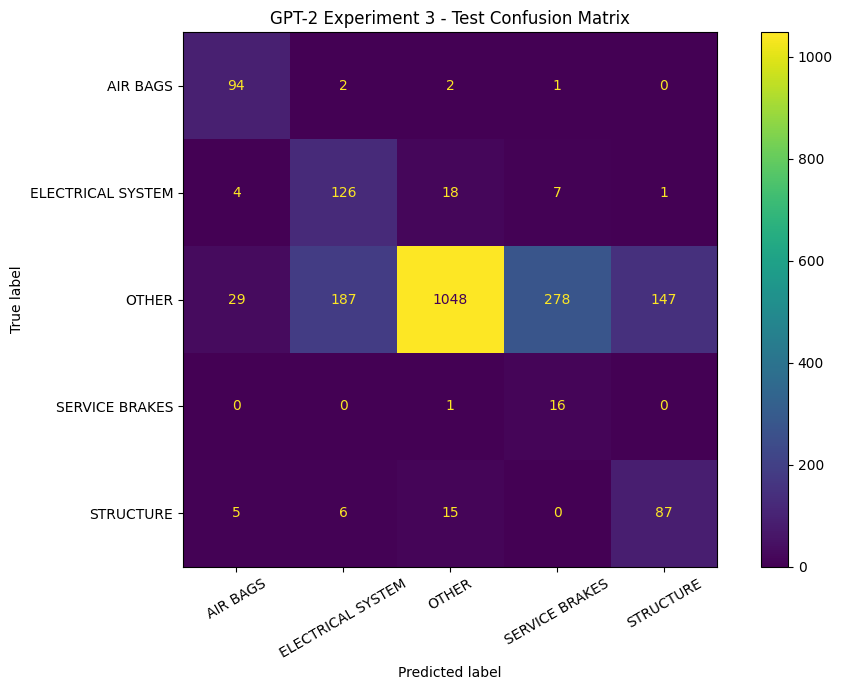

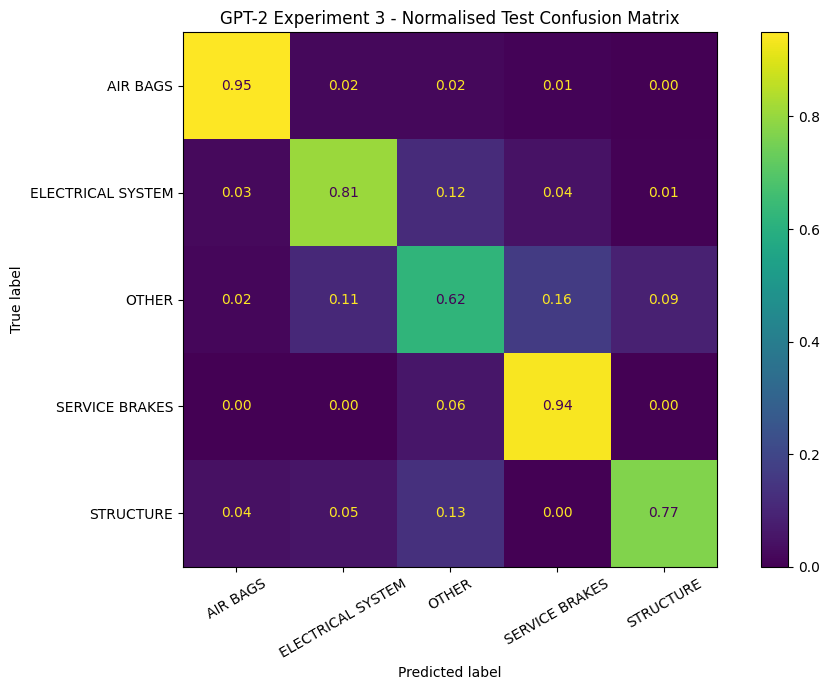

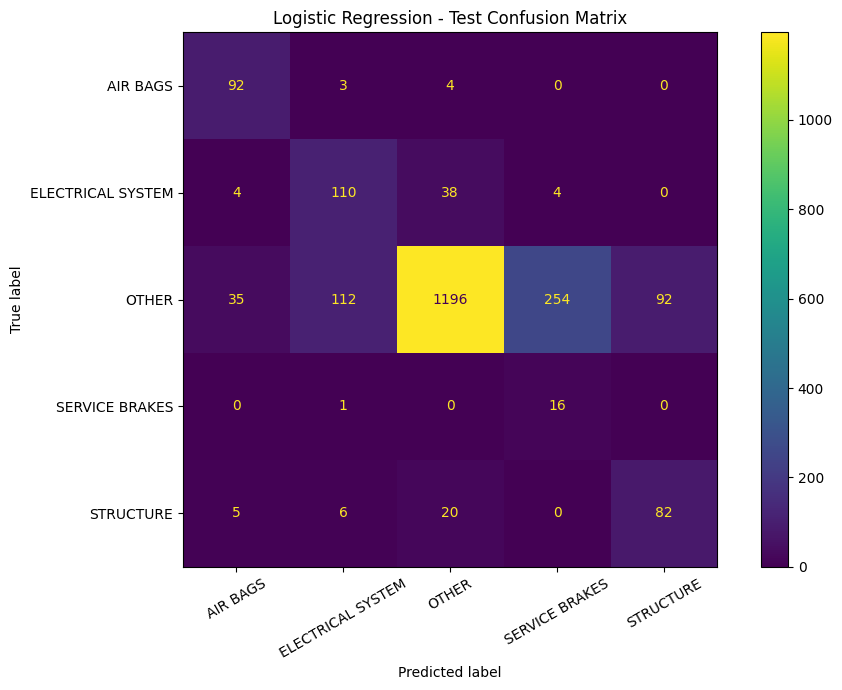

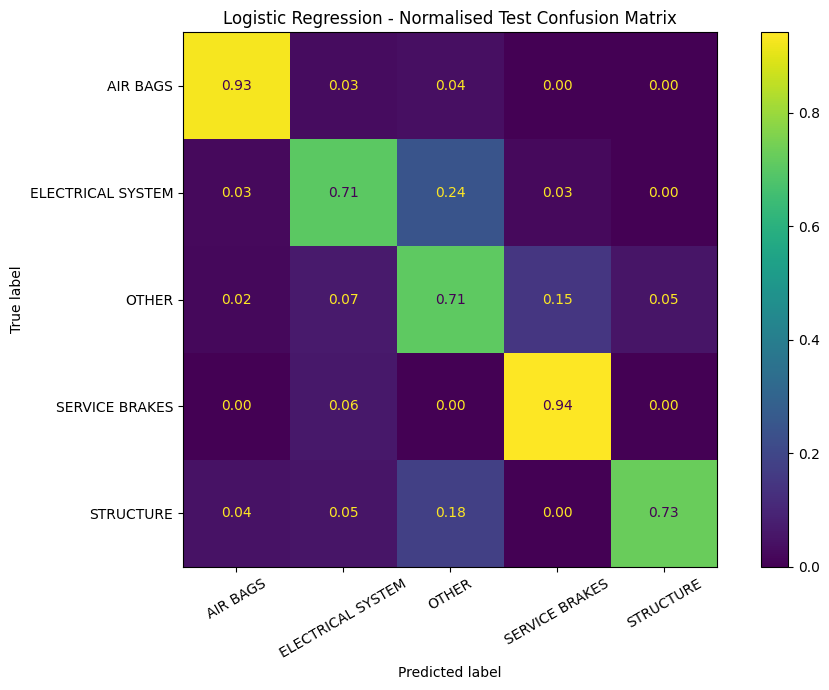


ACTUAL VERSUS PREDICTED CLASS DISTRIBUTION


,Category,Actual,GPT-2 Predicted,Baseline Predicted
0,AIR BAGS,99,132,136
1,ELECTRICAL SYSTEM,156,321,232
2,OTHER,1689,1084,1258
3,SERVICE BRAKES,17,302,274
4,STRUCTURE,113,235,174



SUCCESS: Confusion matrices and class counts saved.


In [20]:

# SECTION 10 - FINAL CONFUSION MATRICES
# Uses the independent test predictions.


from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay

results_dir = Path(OUTPUT) / "results"
results_dir.mkdir(parents=True, exist_ok=True)

y_true = test_df["label_id"].to_numpy()

model_predictions = {
    "GPT-2 Experiment 3": np.asarray(gpt_test_pred),
    "Logistic Regression": np.asarray(base_test_pred)
}

class_ids = list(range(len(ALL_LABELS)))

for model_name, predictions in model_predictions.items():

    safe_name = model_name.lower().replace(" ", "_").replace("-", "_")

    # Create a confusion matrix showing actual counts.
    fig, ax = plt.subplots(figsize=(10, 7))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions,
        labels=class_ids,
        display_labels=ALL_LABELS,
        values_format="d",
        ax=ax,
        xticks_rotation=30
    )

    ax.set_title(f"{model_name} - Test Confusion Matrix")
    plt.tight_layout()

    plt.savefig(
        results_dir / f"{safe_name}_confusion_matrix.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    # Normalise by actual class.
    fig, ax = plt.subplots(figsize=(10, 7))

    ConfusionMatrixDisplay.from_predictions(
        y_true,
        predictions,
        labels=class_ids,
        display_labels=ALL_LABELS,
        normalize="true",
        values_format=".2f",
        ax=ax,
        xticks_rotation=30
    )

    ax.set_title(
        f"{model_name} - Normalised Test Confusion Matrix"
    )

    plt.tight_layout()

    plt.savefig(
        results_dir / f"{safe_name}_normalised_confusion_matrix.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

# Compare actual versus predicted category counts.
prediction_counts = pd.DataFrame({
    "Category": ALL_LABELS,
    "Actual": np.bincount(
        y_true, minlength=len(ALL_LABELS)
    ),
    "GPT-2 Predicted": np.bincount(
        gpt_test_pred, minlength=len(ALL_LABELS)
    ),
    "Baseline Predicted": np.bincount(
        base_test_pred, minlength=len(ALL_LABELS)
    )
})

prediction_counts.to_csv(
    results_dir / "test_prediction_class_distribution.csv",
    index=False
)

print("\nACTUAL VERSUS PREDICTED CLASS DISTRIBUTION")
display(prediction_counts)

print("\nSUCCESS: Confusion matrices and class counts saved.")


## 11 - Demonstrating Inference on Complaints which are New and Hypothetical


In [22]:

# SECTION 11 - DEMONSTRATION FOR FINAL GPT-2 CLASSIFICATION
# Model: Experiment 3 (256 tokens, 5 epochs, 3 blocks)

import torch
from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

# Load the saved Experiment 3 model.
FINAL_MODEL_DIR = (
    OUTPUT
    / "experiments"
    / "gpt2_256tokens_5epochs_3blocks"
    / "model"
)

assert (FINAL_MODEL_DIR / "config.json").exists(), \
    "Saved Experiment 3 model not found."

demo_tokenizer = AutoTokenizer.from_pretrained(
    FINAL_MODEL_DIR
)

demo_model = AutoModelForSequenceClassification.from_pretrained(
    FINAL_MODEL_DIR
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

demo_model.to(device)
demo_model.eval()

print("Final GPT-2 model loaded successfully.")
print("Device:", device)

# Classify a new vehicle complaint.
def classify_vehicle_complaint(text):

    encoded = demo_tokenizer(
        text,
        truncation=True,
        max_length=256,
        return_tensors="pt"
    )

    encoded = {
        key: value.to(device)
        for key, value in encoded.items()
    }

    with torch.inference_mode():
        outputs = demo_model(**encoded)
        probabilities = torch.softmax(
            outputs.logits.float(),
            dim=-1
        )[0]

    predicted_id = int(torch.argmax(probabilities))

    return {
        "predicted_category":
            demo_model.config.id2label[predicted_id],
        "model_probability":
            round(float(probabilities[predicted_id]), 4)
    }


# New vehicle complaints.
examples = [
    "The airbag warning light remains on and the airbag failed to deploy during a collision.",

    "The dashboard lights suddenly went off and the vehicle stalled because of an electrical failure.",

    "The brake pedal feels soft and the vehicle takes longer than normal to stop.",

    "Severe corrosion has developed on the vehicle frame near the rear suspension.",

    "The vehicle's tyres are wearing unevenly and excessive road noise is coming from the wheels."
]

print("\nFINAL GPT-2 CLASSIFICATION DEMONSTRATION\n")

for number, complaint in enumerate(examples, start=1):

    result = classify_vehicle_complaint(complaint)

    print(f"Example {number}")
    print("Complaint:", complaint)
    print("Predicted category:",
          result["predicted_category"])
    print("Model probability:",
          result["model_probability"])
    print("-" * 70)

print("\nSUCCESS: Final model demonstration completed.")


Final GPT-2 model loaded successfully.
Device: cuda

FINAL GPT-2 CLASSIFICATION DEMONSTRATION

Example 1
Complaint: The airbag warning light remains on and the airbag failed to deploy during a collision.
Predicted category: AIR BAGS
Model probability: 0.9954
----------------------------------------------------------------------
Example 2
Complaint: The dashboard lights suddenly went off and the vehicle stalled because of an electrical failure.
Predicted category: ELECTRICAL SYSTEM
Model probability: 0.9886
----------------------------------------------------------------------
Example 3
Complaint: The brake pedal feels soft and the vehicle takes longer than normal to stop.
Predicted category: SERVICE BRAKES
Model probability: 0.966
----------------------------------------------------------------------
Example 4
Complaint: Severe corrosion has developed on the vehicle frame near the rear suspension.
Predicted category: STRUCTURE
Model probability: 0.9896
---------------------------------

## 12 - Packaging Results and Finishing the Experiment Log


In [23]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

root = Path(OUTPUT)
results_dir = root / "results"

zip_path = root / "CP5403_Final_Project_Evidence.zip"

# Include safe results and evaluation outputs.
evidence_files = []

result_names = [
    "metrics.json",
    "model_comparison.csv",
    "final_test_comparison.csv",
    "test_predictions_labels_only.csv",
    "gpt2_test_per_class_report.csv",
    "baseline_test_per_class_report.csv",
    "validation_experiment_comparison.csv",
    "validation_comparison_3experiments.csv",
    "test_prediction_class_distribution.csv"
]

for name in result_names:
    p = results_dir / name
    if p.is_file():
        evidence_files.append(p)

# Include saved evaluation charts.
evidence_files.extend(results_dir.glob("*.png"))

# Include all three experiment histories and metrics.
for experiment_dir in (root / "experiments").glob("*"):
    for filename in [
        "validation_metrics.json",
        "training_history.csv"
    ]:
        p = experiment_dir / filename
        if p.is_file():
            evidence_files.append(p)

# Include available cleaning reports.
for p in [
    root / "data_quality.json",
    root / "data" / "data_quality.json"
]:
    if p.is_file():
        evidence_files.append(p)

# Create an evidence-only ZIP.
# Raw complaint texts and large model weights are excluded.
with ZipFile(zip_path, "w", ZIP_DEFLATED) as archive:
    for p in sorted(set(evidence_files)):
        archive.write(p, arcname=p.relative_to(root))

print("Evidence archive created:", zip_path)
print("Files included:", len(set(evidence_files)))

for p in sorted(set(evidence_files)):
    print("-", p.relative_to(root))

# Download to computer.
files.download(str(zip_path))


Evidence archive created: /content/automotive_cp5403_outputs/CP5403_Final_Project_Evidence.zip
Files included: 18
- experiments/gpt2_128tokens_2epochs/training_history.csv
- experiments/gpt2_128tokens_2epochs/validation_metrics.json
- experiments/gpt2_256tokens_3epochs/training_history.csv
- experiments/gpt2_256tokens_3epochs/validation_metrics.json
- experiments/gpt2_256tokens_5epochs_3blocks/training_history.csv
- experiments/gpt2_256tokens_5epochs_3blocks/validation_metrics.json
- results/baseline_test_per_class_report.csv
- results/gpt2_test_per_class_report.csv
- results/gpt_2_experiment_3_confusion_matrix.png
- results/gpt_2_experiment_3_normalised_confusion_matrix.png
- results/logistic_regression_confusion_matrix.png
- results/logistic_regression_normalised_confusion_matrix.png
- results/metrics.json
- results/model_comparison.csv
- results/test_prediction_class_distribution.csv
- results/test_predictions_labels_only.csv
- results/validation_comparison_3experiments.csv
- result

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13 - Backing up Trained Model to Google Drive

In [27]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

source = (
    Path(OUTPUT)
    / "experiments"
    / "gpt2_256tokens_5epochs_3blocks"
    / "model"
)

destination = Path(
    "/content/drive/MyDrive/"
    "CP5403_Automotive_Project/final_gpt2_model_colab_backup"
)

assert (source / "config.json").exists()
assert any(source.glob("*.safetensors"))

destination.parent.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)

print("Final model backed up successfully.")
print("Google Drive location:", destination)


Mounted at /content/drive
Final model backed up successfully.
Google Drive location: /content/drive/MyDrive/CP5403_Automotive_Project/final_gpt2_model_colab_backup


**Alternative Backup**

In [25]:

from pathlib import Path
from zipfile import ZipFile, ZIP_STORED
from google.colab import files

model_dir = Path(
    "/content/automotive_cp5403_outputs/"
    "experiments/gpt2_256tokens_5epochs_3blocks/model"
)

# Verify the trained model exists.
assert (model_dir / "config.json").exists(), \
    "Model configuration not found."

assert any(model_dir.glob("*.safetensors")), \
    "Trained model weights not found."

# Create the model backup.
zip_path = Path(
    "/content/CP5403_Final_GPT2_Experiment3_Model.zip"
)

with ZipFile(
    zip_path,
    "w",
    compression=ZIP_STORED,
    allowZip64=True
) as archive:

    for file_path in model_dir.rglob("*"):
        if file_path.is_file():
            archive.write(
                file_path,
                arcname=file_path.relative_to(
                    model_dir.parent
                )
            )

print("SUCCESS: Final GPT-2 model backup created.")
print("Backup file:", zip_path)
print("Size (MB):", round(
    zip_path.stat().st_size / (1024 ** 2), 2
))

# Download to computer.
files.download(str(zip_path))

SUCCESS: Final GPT-2 model backup created.
Backup file: /content/CP5403_Final_GPT2_Experiment3_Model.zip
Size (MB): 479.32


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>